# 03 · Décision et ROI
Ce notebook couvre les axes 6 (coûts, seuil) et 7 (ROI). Il utilise les probabilités enregistrées par le notebook 02 :
- **seuil choisi sur le train** (probabilités hors pli) ;
- **résultat annoncé sur le test**.

À lancer **après** le notebook 02.

## 1. Imports et données

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.utils import table_seuils, choisir_seuil

REPORTS = Path("..") / "reports"
sns.set_theme(style="whitegrid")

train = pd.read_csv(REPORTS / "proba_train_oof.csv")
test = pd.read_csv(REPORTS / "proba_test.csv")
print("Train :", train.shape, "| Test :", test.shape)

Train : (8000, 2) | Test : (2000, 2)


## 2. Hypothèses de coûts
**Toutes ces valeurs sont des HYPOTHÈSES, à ajuster et à justifier dans le rapport.** Aucune n'est issue d'une source.
Modifiez-les, puis relancez le notebook : tous les résultats s'actualisent.

**Règle de décision :** si la probabilité d'instabilité est ≥ seuil, on lance la simulation complète ; sinon on applique le réglage directement.

| Cas | Conséquence | Coût |
|---|---|---|
| Vrai positif (instable détecté) | simulation lancée, réglage corrigé | `C_SIM` |
| Faux positif (stable jugé instable) | simulation inutile | `C_SIM` |
| Faux négatif (instable non détecté) | réglage instable appliqué : incident | `C_FN` |
| Vrai négatif (stable jugé stable) | réglage appliqué directement | 0 |
| **Sans modèle (situation actuelle)** | **simulation de tous les réglages** | `N_AN × C_SIM` |

In [2]:
# ---- HYPOTHÈSES (à adapter et à justifier dans le rapport) ----
N_AN = 20_000          # réglages testés par an
DUREE_SIM_H = 0.5      # durée d'une simulation complète (heures)
COUT_HORAIRE = 60.0    # coût horaire ingénieur + calcul (€/h)
C_SIM = DUREE_SIM_H * COUT_HORAIRE      # coût d'une simulation (€)
C_FN = 2_000.0         # coût d'un réglage instable appliqué sans détection (€)

COUT_DEV = 8_000.0     # développement du projet, année 1 (€)
COUT_EXPLOIT = 2_000.0 # exploitation et réentraînement, année 1 (€)
COUT_PROJET = COUT_DEV + COUT_EXPLOIT

RECALL_MIN = 0.95      # critère de succès du cadrage : détecter au moins 95 % des instables

print(f"Coût d'une simulation : {C_SIM:.0f} € | coût d'un faux négatif : {C_FN:.0f} €")
print(f"Coût du projet (année 1) : {COUT_PROJET:.0f} €")

Coût d'une simulation : 30 € | coût d'un faux négatif : 2000 €
Coût du projet (année 1) : 10000 €


## 3. Analyse des seuils (sur le train, probabilités hors pli)

In [3]:
seuils_exemple = [0.1, 0.2, 0.3, 0.5, 0.7]
t = table_seuils(train["y"], train["proba"], seuils_exemple, C_FN, C_SIM, N_AN)
affichage = t.copy()
for c in ["precision", "recall", "simu_evitees"]:
    affichage[c] = (affichage[c] * 100).round(1).astype(str) + " %"
affichage["f1"] = affichage["f1"].round(3)
for c in ["cout_avec_modele", "cout_sans_modele", "gain_annuel"]:
    affichage[c] = affichage[c].round(0).astype(int)
affichage

,seuil,TP,FP,FN,TN,precision,recall,f1,simu_evitees,cout_avec_modele,cout_sans_modele,gain_annuel
0,0.1,5104,1692,0,1204,75.1 %,100.0 %,0.858,15.0 %,509700,600000,90300
1,0.2,5095,1188,9,1708,81.1 %,99.8 %,0.895,21.5 %,516225,600000,83775
2,0.3,5057,873,47,2023,85.3 %,99.1 %,0.917,25.9 %,679750,600000,-79750
3,0.5,4861,379,243,2517,92.8 %,95.2 %,0.940,34.5 %,1608000,600000,-1008000
4,0.7,4408,92,696,2804,98.0 %,86.4 %,0.918,43.8 %,3817500,600000,-3217500


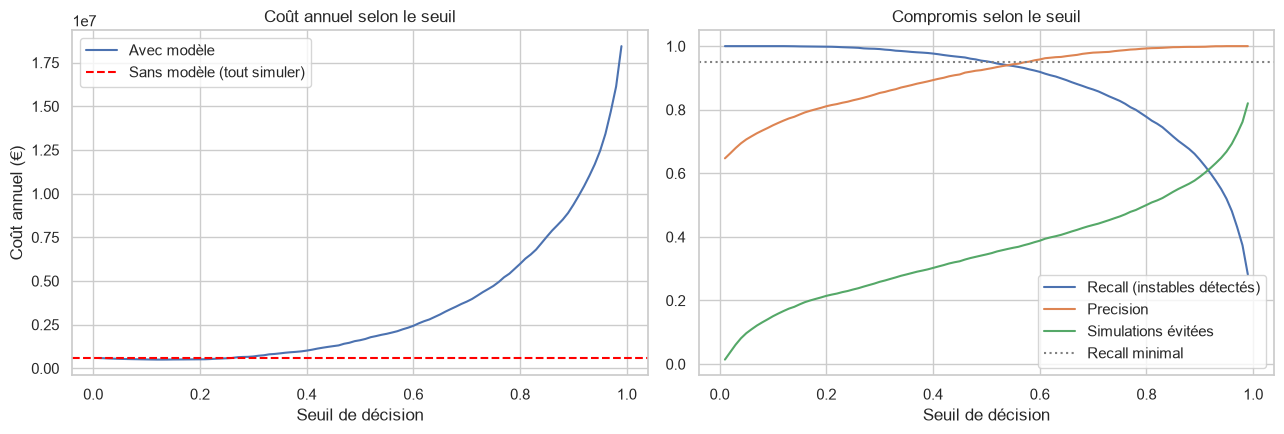

In [4]:
seuils_fins = np.round(np.arange(0.01, 1.0, 0.01), 2)
t_fin = table_seuils(train["y"], train["proba"], seuils_fins, C_FN, C_SIM, N_AN)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(t_fin["seuil"], t_fin["cout_avec_modele"], label="Avec modèle")
ax[0].axhline(t_fin["cout_sans_modele"].iloc[0], color="red", linestyle="--", label="Sans modèle (tout simuler)")
ax[0].set_xlabel("Seuil de décision")
ax[0].set_ylabel("Coût annuel (€)")
ax[0].set_title("Coût annuel selon le seuil")
ax[0].legend()

ax[1].plot(t_fin["seuil"], t_fin["recall"], label="Recall (instables détectés)")
ax[1].plot(t_fin["seuil"], t_fin["precision"], label="Precision")
ax[1].plot(t_fin["seuil"], t_fin["simu_evitees"], label="Simulations évitées")
ax[1].axhline(RECALL_MIN, color="grey", linestyle=":", label="Recall minimal")
ax[1].set_xlabel("Seuil de décision")
ax[1].set_title("Compromis selon le seuil")
ax[1].legend()
plt.tight_layout()
plt.show()

**Interprétation (à rédiger) :** à quel seuil le coût est-il minimal ? Ce seuil respecte-t-il le recall minimal de 95 % ?
Pourquoi le seuil par défaut de 0,5 n'est-il pas le meilleur choix ici ?

## 4. Seuil retenu
On retient le seuil de coût minimal **parmi ceux qui respectent le recall minimal** (critère de succès de la note de cadrage).
Si aucun seuil ne le respecte, on prend le seuil de coût minimal (le notebook l'indique).

In [5]:
SEUIL = choisir_seuil(t_fin, RECALL_MIN)
ligne = t_fin[t_fin["seuil"] == SEUIL].iloc[0]
print(f"Seuil retenu : {SEUIL}")
if ligne["recall"] < RECALL_MIN:
    print("ATTENTION : aucun seuil ne respecte le recall minimal ; seuil de coût minimal retenu.")
print(f"Sur le train (validation croisée) : recall {ligne['recall']:.1%}, precision {ligne['precision']:.1%}, "
      f"simulations évitées {ligne['simu_evitees']:.1%}")

Seuil retenu : 0.12
Sur le train (validation croisée) : recall 100.0%, precision 76.6%, simulations évitées 16.7%


## 5. Résultat sur le jeu de test (seuil fixé sur le train)
Le seuil n'est **pas** réajusté sur le test.

In [6]:
res_test = table_seuils(test["y"], test["proba"], [0.5, SEUIL], C_FN, C_SIM, N_AN)
res_test["seuil_utilise"] = ["0,5 (défaut)", f"{SEUIL} (retenu)"]
vue = res_test[["seuil_utilise", "TP", "FP", "FN", "TN", "precision", "recall", "simu_evitees", "gain_annuel"]].copy()
for c in ["precision", "recall", "simu_evitees"]:
    vue[c] = (vue[c] * 100).round(1).astype(str) + " %"
vue["gain_annuel"] = vue["gain_annuel"].round(0).astype(int)
vue

,seuil_utilise,TP,FP,FN,TN,precision,recall,simu_evitees,gain_annuel
0,"0,5 (défaut)",1235,88,41,636,93.3 %,96.8 %,33.8 %,-616900
1,0.12 (retenu),1276,401,0,323,76.1 %,100.0 %,16.2 %,96900


In [7]:
r = res_test.iloc[1]
n_inst = int(r["TP"] + r["FN"])
print(f"Traduction métier au seuil {SEUIL} : sur 100 réglages instables, le modèle en détecte "
      f"{r['recall'] * 100:.0f}.")
print(f"Il évite {r['simu_evitees'] * 100:.0f} % des simulations ; "
      f"{int(r['FN'])} instable(s) non détecté(s) sur {n_inst} dans le jeu de test.")

Traduction métier au seuil 0.12 : sur 100 réglages instables, le modèle en détecte 100.
Il évite 16 % des simulations ; 0 instable(s) non détecté(s) sur 1276 dans le jeu de test.


## 6. ROI (année 1)
Formules des consignes :
- Gain annuel = coût sans modèle − coût avec modèle
- ROI (%) = (gain annuel − coût du projet) / coût du projet × 100
- Délai de retour (mois) = coût du projet / (gain annuel / 12)

In [8]:
def roi(gain_annuel, cout_projet):
    roi_pct = (gain_annuel - cout_projet) / cout_projet * 100
    retour_mois = cout_projet / (gain_annuel / 12) if gain_annuel > 0 else float("inf")
    return roi_pct, retour_mois

gain = r["gain_annuel"]
roi_pct, retour = roi(gain, COUT_PROJET)
print(f"Coût sans modèle : {r['cout_sans_modele']:.0f} € | avec modèle : {r['cout_avec_modele']:.0f} €")
print(f"Gain annuel : {gain:.0f} € | coût du projet : {COUT_PROJET:.0f} €")
print(f"ROI année 1 : {roi_pct:.0f} % | retour sur investissement : {retour:.1f} mois")

Coût sans modèle : 600000 € | avec modèle : 503100 €
Gain annuel : 96900 € | coût du projet : 10000 €
ROI année 1 : 869 % | retour sur investissement : 1.2 mois


## 7. Analyse de sensibilité
Pour chaque scénario, on **recalcule le seuil sur le train** puis on évalue sur le test. Les coûts sont des hypothèses : on regarde de quoi dépend le résultat.

In [9]:
def scenario(nom, c_fn, c_sim, n_an, cout_projet):
    t_tr = table_seuils(train["y"], train["proba"], seuils_fins, c_fn, c_sim, n_an)
    s = choisir_seuil(t_tr, RECALL_MIN)
    ligne = table_seuils(test["y"], test["proba"], [s], c_fn, c_sim, n_an).iloc[0]
    roi_pct, retour = roi(ligne["gain_annuel"], cout_projet)
    return {"Scénario": nom, "C_FN (€)": c_fn, "C_SIM (€)": c_sim, "Réglages/an": n_an,
            "Seuil": s, "Recall test": f"{ligne['recall']:.1%}",
            "Simu. évitées": f"{ligne['simu_evitees']:.1%}",
            "Gain annuel (€)": round(ligne["gain_annuel"]),
            "ROI an 1 (%)": round(roi_pct),
            "Retour (mois)": round(retour, 1) if retour != float("inf") else "jamais"}

scenarios = [
    scenario("Central", C_FN, C_SIM, N_AN, COUT_PROJET),
    scenario("Pessimiste : incident 5x plus cher", C_FN * 5, C_SIM, N_AN, COUT_PROJET),
    scenario("Pessimiste : simulation 3x moins chère", C_FN, C_SIM / 3, N_AN, COUT_PROJET),
    scenario("Pessimiste : 4x moins de réglages/an", C_FN, C_SIM, N_AN // 4, COUT_PROJET),
    scenario("Optimiste : simulation 2x plus chère", C_FN, C_SIM * 2, N_AN, COUT_PROJET),
]
pd.DataFrame(scenarios)

,Scénario,C_FN (€),C_SIM (€),Réglages/an,Seuil,Recall test,Simu. évitées,Gain annuel (€),ROI an 1 (%),Retour (mois)
0,Central,2000.0,30.0,20000,0.12,100.0%,16.2%,96900,869,1.2
1,Pessimiste : incident 5x plus cher,10000.0,30.0,20000,0.12,100.0%,16.2%,96900,869,1.2
2,Pessimiste : simulation 3x moins chère,2000.0,10.0,20000,0.12,100.0%,16.2%,32300,223,3.7
3,Pessimiste : 4x moins de réglages/an,2000.0,30.0,5000,0.12,100.0%,16.2%,24225,142,5.0
4,Optimiste : simulation 2x plus chère,2000.0,60.0,20000,0.20,100.0%,21.4%,256800,2468,0.5


**Lecture (à rédiger) :**
- Le projet reste-t-il rentable dans le scénario pessimiste ? Quelle hypothèse fait le plus bouger le résultat ?
- Quelle hypothèse faudrait-il valider en priorité auprès d'un gestionnaire de réseau ?
- **Recommandation (une phrase) :** déployer, ne pas déployer, ou piloter sur un périmètre limité, et pourquoi.

⚠️ Ne présentez pas le ROI comme une certitude : les coûts sont posés par hypothèse, et les données sont simulées sur un réseau simplifié à 4 nœuds.